# Abalone Dataset: Model Training

The target for this data set is `Rings`
Current process is importing the original dataset and splitting it first, then performing pre-processing(ref from abalone_eda_preprocessing).

## 1. Imports and configuration

Init require lbry and setting var



In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

DATA_PATH = Path("data/abalone.data")  # change this if the file is elsewhere
RANDOM_STATE = 42

FEATURE_NAMES = [
    "Sex", "Length", "Diameter", "Height", "Whole weight",
    "Shucked weight", "Viscera weight", "Shell weight", "Rings"
]
TARGET = "Rings"
CATEGORICAL_FEATURES = ["Sex"]
NUMERIC_COLUMNS = [c for c in FEATURE_NAMES if c not in CATEGORICAL_FEATURES]
PREDICTOR_NUMERIC = [c for c in NUMERIC_COLUMNS if c != TARGET]

## 2. Load the original data

The original UCI file has no header row and uses comma-separated values. It contains 9 columns: `Sex` as a category, seven physical measurements, and `Rings`.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Put abalone.data beside this notebook "
        "or update DATA_PATH to the correct location."
    )

df = pd.read_csv(DATA_PATH, header=None, names=FEATURE_NAMES, skipinitialspace=True)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows: 4,177 | Columns: 9


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


,dtype
Sex,str
Length,float64
Diameter,float64
Height,float64
Whole weight,float64
Shucked weight,float64
Viscera weight,float64
Shell weight,float64
Rings,int64


## 3. Training/Test Dataset split

- `CLASS_THRESHOLD` = 10 (`Rings >= 10`)
- `y_reg`: original Rings values (Random Forest Regressor/Linear Regression)
- `y_clf`: `1` if `Rings >= CLASS_THRESHOLD` (binary for Logistic Regression)

No preprocessing before the split

In [3]:
from sklearn.model_selection import train_test_split

CLASS_THRESHOLD = 10  # classification = 1 if Rings >= 10

X = df.drop(columns=[TARGET]).copy()
y_reg = df[TARGET].copy()
y_clf = (df[TARGET] >= CLASS_THRESHOLD).astype(int)

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_clf
)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_reg_train, y_reg_test = y_reg.loc[train_idx], y_reg.loc[test_idx]
y_clf_train, y_clf_test = y_clf.loc[train_idx], y_clf.loc[test_idx]

print(f"Train: {len(X_train)} rows; Test: {len(X_test)} rows")

Train: 3341 rows; Test: 836 rows


## 4. Preprocessing pipelines
This section may be modified when eda-processing is changed (might be merged into separate file later).

Use a scikit-learn `Pipeline`/`ColumnTransformer` so imputation, encoding, and scaling are fitted on training folds only as to prevent leakage.

In [4]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numeric_transform_standard = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transform = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_standard = ColumnTransformer(transformers=[
    ("numeric", numeric_transform_standard, PREDICTOR_NUMERIC),
    ("categorical", categorical_transform, CATEGORICAL_FEATURES)
])

numeric_transform_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("numeric", numeric_transform_tree, PREDICTOR_NUMERIC),
    ("categorical", categorical_transform, CATEGORICAL_FEATURES)
])

print("Success pre-processing for Random Forest, linear regression and logistic regression.")

Success pre-processing for Random Forest, linear regression and logistic regression.


## 5. Random Forest Regression
n_estimators = 200

In [5]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = Pipeline(steps=[
    ("preprocessing", preprocessor_tree),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
    ))
])

rf_reg.fit(X_train, y_reg_train)
rf_predictions = rf_reg.predict(X_test)
print("Success")

Success


## 6. Logistic Regression(Classification Algorithm)
Predict whether `Rings >= CLASS_THRESHOLD`.


In [6]:
from sklearn.linear_model import LogisticRegression

logistic_clf = Pipeline(steps=[
    ("preprocessing", preprocessor_standard),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

logistic_clf.fit(X_train, y_clf_train)
logistic_predictions = logistic_clf.predict(X_test)
logistic_probabilities = logistic_clf.predict_proba(X_test)[:, 1]
print("Success")

Success


## 7. Linear Regression (Backup model)

In [7]:
from sklearn.linear_model import LinearRegression

linear_reg = Pipeline(steps=[
    ("preprocessing", preprocessor_standard),
    ("model", LinearRegression())
])

linear_reg.fit(X_train, y_reg_train)
linear_predictions = linear_reg.predict(X_test)
print("Success")

Success


## 8. Final evaluation of all models
Evaluate models' score

Visualize the comparison of model score(logistic regression/classification can not compare to other regression model)

In [8]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, 
)

def regression_scores(model, y_true, y_pred):
    return {
        "model": model,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R^2": r2_score(y_true, y_pred)
    }

regression_metrics = pd.DataFrame([
    regression_scores("Random Forest Regressor", y_reg_test, rf_predictions),
    regression_scores("Linear Regression", y_reg_test, linear_predictions)
])

classification_metrics = pd.DataFrame([{
    "model": "Logistic Regression",
    "threshold_rings": CLASS_THRESHOLD,
    "Accuracy": accuracy_score(y_clf_test, logistic_predictions),
    "Precision": precision_score(y_clf_test, logistic_predictions, zero_division=0),
    "Recall": recall_score(y_clf_test, logistic_predictions, zero_division=0),
    "F1": f1_score(y_clf_test, logistic_predictions, zero_division=0),
    "ROC_AUC": roc_auc_score(y_clf_test, logistic_probabilities)
}])

display(regression_metrics.round(4))
display(classification_metrics.round(4))

,model,MAE,RMSE,R^2
0,Random Forest Regressor,1.5373,2.1436,0.5229
1,Linear Regression,1.5846,2.2126,0.4917


,model,threshold_rings,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,10,0.7859,0.7985,0.762,0.7798,0.8709


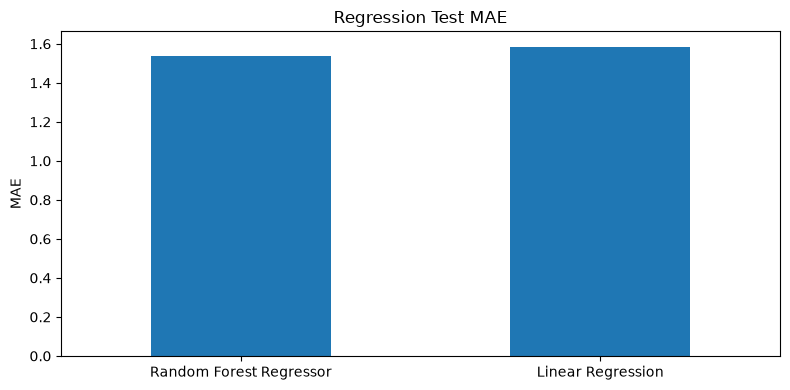

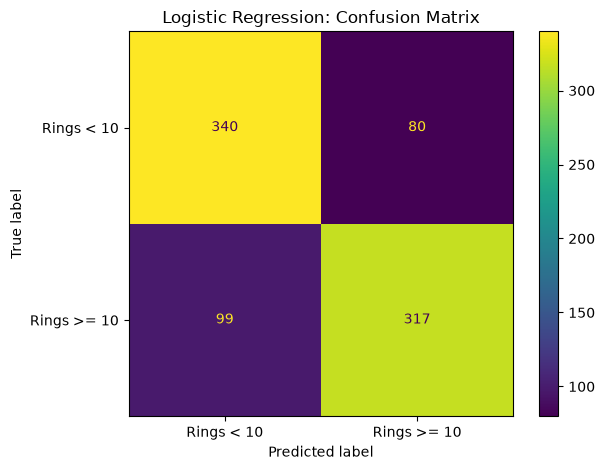

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

# Regression Test MAE
ax = regression_metrics.plot.bar(x="model", y="MAE", legend=False, rot=0, figsize=(8, 4))
ax.set_title("Regression Test MAE")
ax.set_ylabel("MAE")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

# Classification
ConfusionMatrixDisplay.from_predictions(
    y_clf_test,
    logistic_predictions,
    display_labels=[f"Rings < {CLASS_THRESHOLD}", f"Rings >= {CLASS_THRESHOLD}"]
)
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Export Result
Output the model's predicted answer to the .csv file in result folder.

In [10]:
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

regression_predictions = pd.DataFrame({
    "original_row_index": X_test.index.to_numpy(),
    "actual_rings": y_reg_test.to_numpy(),
    "random_forest_pred_rings": rf_predictions,
    "linear_regression_pred_rings": linear_predictions
})

classification_predictions = pd.DataFrame({
    "original_row_index": X_test.index.to_numpy(),
    "actual_rings": y_reg_test.to_numpy(),
    "actual_class": y_clf_test.to_numpy(),
    "logistic_pred_class": logistic_predictions,
    "logistic_prob_class_1": logistic_probabilities
})

regression_predictions.to_csv(results_dir / "regression_predictions.csv", index=False)
classification_predictions.to_csv(results_dir / "classification_predictions.csv", index=False)

print("Success export files in results folder")

Success export files in results folder
